# Deep Learning-Based Brain Lesion Segmentation from MRI

### Project Overview

This project presents a deep learning-based medical image segmentation pipeline for brain lesion segmentation using the MOTUM v2.2 MRI dataset.

The notebook implements an end-to-end workflow covering dataset preparation, preprocessing, patient-level data splitting, model training, validation, checkpoint management, and quantitative evaluation.

The segmentation model contains approximately 2.03 million trainable parameters and is evaluated using multiple segmentation metrics, including Dice Similarity Coefficient (DSC), Intersection over Union (IoU), Precision, Recall, F1-score, and 95th Percentile Hausdorff Distance (HD95).

### Dataset
- Dataset: MOTUM v2.2
- Image-mask pairs: 132
- Patients: 66
- Training patients: 46
- Validation patients: 10
- Testing patients: 10

### Experimental Results

| Evaluation Metric | Test Performance |
|---|---:|
| Patient-pooled Dice | 82.75% |
| Patient-pooled IoU | 71.31% |
| Slice Dice | 78.51% |
| Pixel Precision | 83.55% |
| Pixel Recall | 86.65% |
| Pixel F1-score | 85.07% |
| HD95 | 12.12 mm |

### Modality-wise Results

| Modality | Dice | IoU | HD95 |
|---|---:|---:|---:|
| FLAIR | 84.02% | 74.79% | 9.48 mm |
| T1CE | 69.75% | 59.81% | 16.31 mm |

### Research Objectives
1. Develop a deep learning pipeline for MRI-based brain lesion segmentation.
2. Investigate segmentation performance across MRI modalities.
3. Evaluate model performance using overlap-based and boundary-based metrics.
4. Assess generalization using patient-level training, validation, and testing splits.

### Technologies
- Python
- PyTorch
- Google Colab
- NumPy
- Medical image processing libraries
- Deep Learning and Computer Vision

### Note
These results represent the current experimental implementation. Further validation, baseline comparisons, and reproducibility experiments are required before drawing conclusions about clinical performance or superiority over existing methods.

## 2. Environment Setup and Library Installation

This section prepares the Google Colab environment for medical image segmentation research.

The project uses PyTorch for deep learning and MONAI for medical image processing. Additional libraries support MRI data loading, numerical computation, visualisation, and experimental evaluation.

**Required libraries:**
- PyTorch: Deep learning framework.
- MONAI: Medical imaging AI framework.
- NiBabel: Loading and handling NIfTI neuroimaging files.
- SimpleITK: Medical image processing.
- NumPy and Pandas: Data processing.
- Matplotlib: Image visualisation.
- Scikit-learn: Data splitting and evaluation support.

**Objective:** Install the required dependencies and verify that the computational environment is ready for subsequent research activities.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cpu
Dataset root: /content/MOTUM_Dataset/MOTUM-v.2.2
Pairs: 132 | Patients: 66
Split → train 46 | val 10 | test 10
Preparing slices ...
  train: 20/92
  train: 40/92
  train: 60/92
  train: 80/92
  val: 20/20
  test: 20/20
Train slices: 1177 | positive: 795 | negative: 382
Val slices: 237 | Test slices: 237


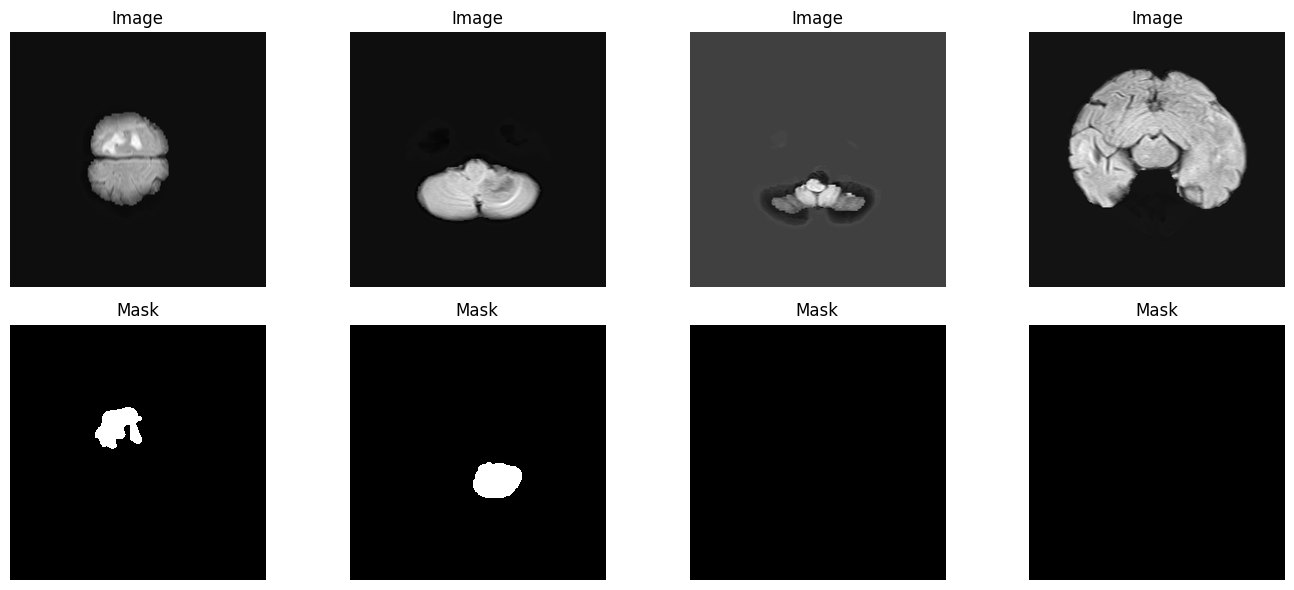

Parameters: 2,029,345
✓ Resumed from 'last' checkpoint: epoch 12 (best Dice 0.6161) → starting epoch 13
Epoch 13/15 | train 0.2649 | val 0.3148 | dice 0.6555 | best 0.6555 | lr 0.000250
Epoch 14/15 | train 0.2601 | val 0.3345 | dice 0.5913 | best 0.6555 | lr 0.000250
Epoch 15/15 | train 0.2587 | val 0.3148 | dice 0.6487 | best 0.6555 | lr 0.000250
Training done. Best val Dice: 0.6555 | time: 44.23 min


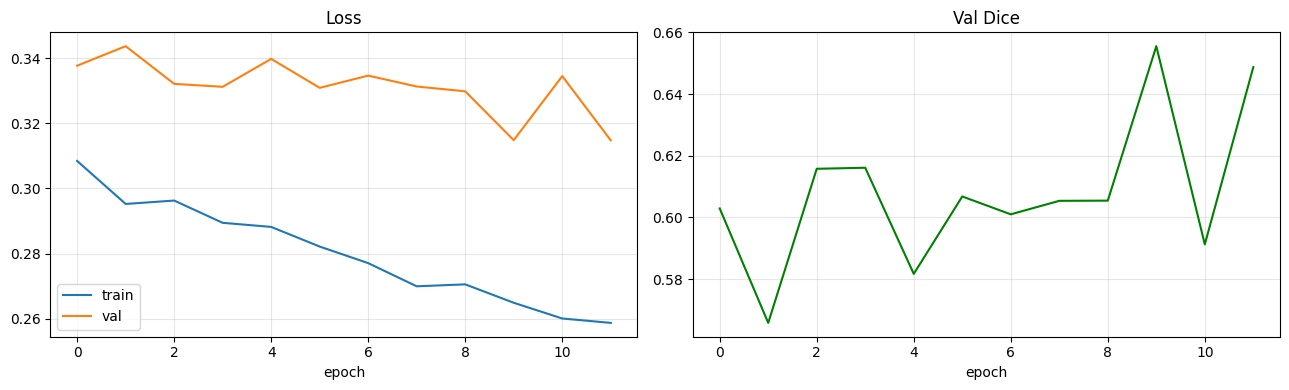

Loaded best epoch: 13

========== TEST RESULTS ==========
Slice Dice (positive only) : 0.7851
Slice IoU  (positive only) : 0.6901
Patient pooled Dice (correct): 0.8275
Patient pooled IoU          : 0.7131
Pixel Precision: 0.8355 | Recall: 0.8665 | F1: 0.8507
HD95 (mm)      : 12.12

Modality-wise:
            dice     iou  hd95_mm
modality                         
flair     0.8402  0.7479   9.4826
t1ce      0.6975  0.5981  16.3115

Patient pooled Dice by modality:
modality
flair    0.8275
Name: pooled_dice, dtype: float64


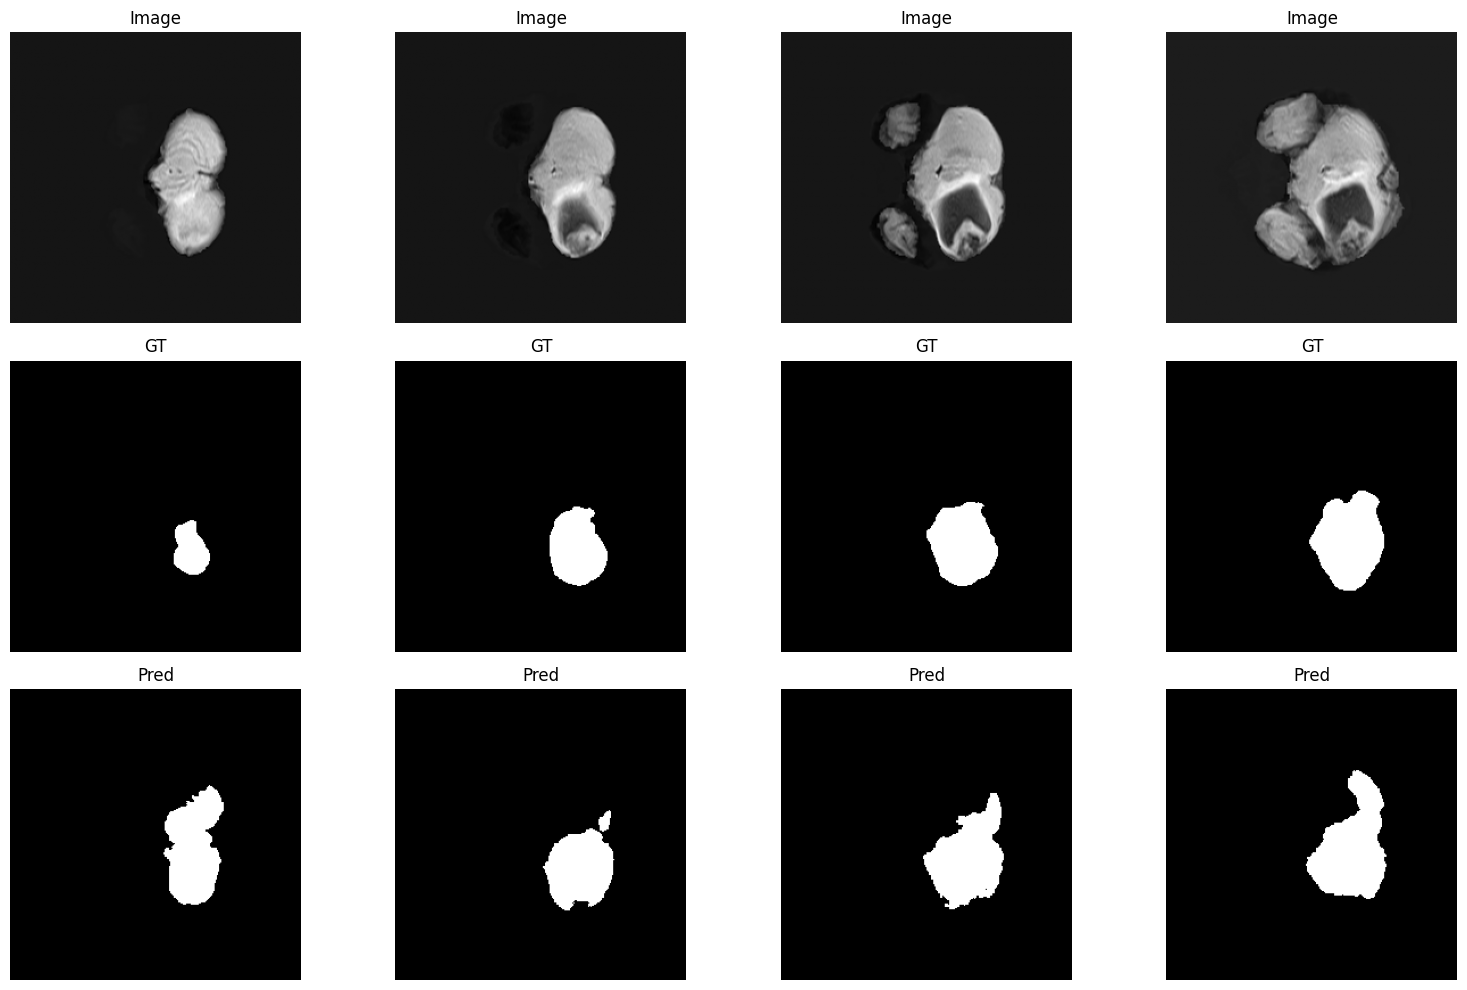


Saved to: /content/drive/MyDrive/MOTUM_Experiment2
Files: ['curves.png', 'experiment2_best_unet.pth', 'experiment2_last_unet.pth', 'history.csv', 'predictions.png', 'summary.csv', 'test_patients.csv', 'test_slices.csv']


In [ ]:
# ================================================================
# MOTUM-v2.2 — RESIDUAL U-NET (RESUME-SAFE, SHORT RUN)
# Saves "last" checkpoint every epoch so a shutdown costs ZERO epochs.
# ================================================================

# -------------------- 1. MOUNT DRIVE ----------------------------
from google.colab import drive
drive.mount('/content/drive')

import os, zipfile, random, shutil, time
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt

from scipy.ndimage import binary_erosion, distance_transform_edt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split

# -------------------- 2. CONFIG ---------------------------------
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", DEVICE)
if DEVICE.type == 'cuda':
    print("GPU:", torch.cuda.get_device_name(0))

ZIP_PATH      = '/content/drive/MyDrive/medical segmentation dataset cv/dataverse_files.zip'
EXTRACT_PATH  = '/content/MOTUM_Dataset'
BASE_PATH     = os.path.join(EXTRACT_PATH, 'MOTUM-v.2.2')
IMG_ROOT      = os.path.join(BASE_PATH, 'images')
DER_ROOT      = os.path.join(BASE_PATH, 'derivatives')
OUTPUT_DIR    = '/content/drive/MyDrive/MOTUM_Experiment2'
os.makedirs(OUTPUT_DIR, exist_ok=True)

IMAGE_SIZE    = 256          # set 128 if CPU-only
BATCH_SIZE    = 8
EPOCHS        = 15           # set 10 if CPU-only
LEARNING_RATE = 5e-4
WEIGHT_DECAY  = 1e-4
PATIENCE      = 5
BASE_CHANNELS = 16
SLICE_AXIS    = 2
NUM_WORKERS   = 2 if DEVICE.type == 'cuda' else 0

# -------------------- 3. EXTRACT --------------------------------
if not os.path.isdir(IMG_ROOT):
    if not os.path.exists(ZIP_PATH):
        raise FileNotFoundError(ZIP_PATH)
    if os.path.exists(EXTRACT_PATH):
        shutil.rmtree(EXTRACT_PATH)
    os.makedirs(EXTRACT_PATH, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, 'r') as z:
        z.extractall(EXTRACT_PATH)
print("Dataset root:", BASE_PATH)

# -------------------- 4. BUILD PAIRS ----------------------------
MODALITY_MAP = {
    'flair': ('flair.nii.gz', 'flair_seg_label1.nii.gz'),
    't1ce':  ('t1ce.nii.gz',  't1ce_seg_label2.nii.gz'),
}

pairs = []
for patient in sorted(os.listdir(IMG_ROOT)):
    img_dir = os.path.join(IMG_ROOT, patient)
    der_dir = os.path.join(DER_ROOT, patient)
    if not os.path.isdir(img_dir) or not os.path.isdir(der_dir):
        continue
    for modality, (img_f, mask_f) in MODALITY_MAP.items():
        ip, mp = os.path.join(img_dir, img_f), os.path.join(der_dir, mask_f)
        if os.path.isfile(ip) and os.path.isfile(mp):
            pairs.append((ip, mp, patient, modality))

patients = sorted({p[2] for p in pairs})
print(f"Pairs: {len(pairs)} | Patients: {len(patients)}")

# -------------------- 5. PATIENT-LEVEL SPLIT --------------------
train_patients, temp = train_test_split(patients, test_size=0.30, random_state=SEED)
val_patients, test_patients = train_test_split(temp, test_size=0.50, random_state=SEED)

train_patients, val_patients, test_patients = set(train_patients), set(val_patients), set(test_patients)
assert not train_patients & val_patients
assert not train_patients & test_patients
assert not val_patients & test_patients

train_pairs = [p for p in pairs if p[2] in train_patients]
val_pairs   = [p for p in pairs if p[2] in val_patients]
test_pairs  = [p for p in pairs if p[2] in test_patients]

print(f"Split → train {len(train_patients)} | val {len(val_patients)} | test {len(test_patients)}")

# -------------------- 6. PREPROCESSING --------------------------
def preprocess_volume(ip, mp):
    img  = nib.load(ip).get_fdata(dtype=np.float32)
    mask = nib.load(mp).get_fdata(dtype=np.float32)
    assert img.shape == mask.shape and img.ndim == 3
    zooms = nib.load(ip).header.get_zooms()[:2]

    nz = img[np.abs(img) > 1e-8]
    if nz.size == 0:
        raise ValueError(f"No nonzero voxels: {ip}")
    img = (img - nz.mean()) / (nz.std() + 1e-8)
    img = np.clip(img, -5, 5)
    mask = (mask > 0).astype(np.float32)
    return img, mask, zooms


def make_slice_indices(mask, max_negatives=2):
    fg = np.where(mask.sum(axis=(0, 1)) > 0)[0]
    selected = set()
    for z in fg:
        selected.add(int(z))
        if z > 0: selected.add(int(z - 1))
        if z < mask.shape[2] - 1: selected.add(int(z + 1))
    negatives = [z for z in range(mask.shape[2]) if z not in selected]
    if negatives:
        n = min(max_negatives, len(negatives))
        idx = np.linspace(0, len(negatives) - 1, n, dtype=int)
        selected.update(negatives[i] for i in idx)
    return sorted(selected)


def resize_slice(img_s, msk_s):
    it = torch.from_numpy(np.ascontiguousarray(img_s)).float()[None, None]
    mt = torch.from_numpy(np.ascontiguousarray(msk_s)).float()[None, None]
    it = F.interpolate(it, size=(IMAGE_SIZE, IMAGE_SIZE), mode='bilinear', align_corners=False)
    mt = F.interpolate(mt, size=(IMAGE_SIZE, IMAGE_SIZE), mode='nearest')
    return it[0, 0].numpy().astype(np.float16), mt[0, 0].numpy().astype(np.uint8)


def prepare_samples(pair_list, name):
    samples = []
    for i, (ip, mp, patient, modality) in enumerate(pair_list):
        img, mask, zooms = preprocess_volume(ip, mp)
        for z in make_slice_indices(mask):
            if SLICE_AXIS == 2:
                s_img, s_msk = img[:, :, z], mask[:, :, z]
            else:
                s_img, s_msk = img[z], mask[z]
            ri, rm = resize_slice(s_img, s_msk)
            samples.append({
                'image': ri, 'mask': rm,
                'patient': patient, 'modality': modality,
                'slice': int(z), 'spacing': tuple(float(x) for x in zooms),
            })
        if (i + 1) % 20 == 0:
            print(f"  {name}: {i+1}/{len(pair_list)}")
    return samples


print("Preparing slices ...")
train_samples = prepare_samples(train_pairs, 'train')
val_samples   = prepare_samples(val_pairs,   'val')
test_samples  = prepare_samples(test_pairs,  'test')

pos_train = sum(1 for s in train_samples if s['mask'].sum() > 0)
print(f"Train slices: {len(train_samples)} | positive: {pos_train} | negative: {len(train_samples)-pos_train}")
print(f"Val slices: {len(val_samples)} | Test slices: {len(test_samples)}")

# -------------------- 7. DATASET --------------------------------
class MOTUMDataset(Dataset):
    def __init__(self, samples, augment=False):
        self.samples = samples
        self.augment = augment

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        s = self.samples[idx]
        img = torch.from_numpy(s['image'].copy()).float().unsqueeze(0)
        msk = torch.from_numpy(s['mask'].copy()).float().unsqueeze(0)
        if self.augment:
            if random.random() < 0.5:
                img, msk = torch.flip(img, [2]), torch.flip(msk, [2])
            if random.random() < 0.5:
                img, msk = torch.flip(img, [1]), torch.flip(msk, [1])
            k = random.randint(0, 3)
            if k:
                img, msk = torch.rot90(img, k, [1, 2]), torch.rot90(msk, k, [1, 2])
            if random.random() < 0.5:
                img = img * random.uniform(0.9, 1.1) + random.uniform(-0.1, 0.1)
        return img, msk


def worker_init_fn(worker_id):
    seed = SEED + worker_id
    random.seed(seed); np.random.seed(seed)


train_ds = MOTUMDataset(train_samples, augment=True)
val_ds   = MOTUMDataset(val_samples,   augment=False)
test_ds  = MOTUMDataset(test_samples,  augment=False)

def make_loader(ds, shuffle):
    return DataLoader(
        ds, batch_size=BATCH_SIZE, shuffle=shuffle,
        num_workers=NUM_WORKERS, worker_init_fn=worker_init_fn,
        pin_memory=(DEVICE.type == 'cuda'), drop_last=False,
    )

train_loader = make_loader(train_ds, True)
val_loader   = make_loader(val_ds,   False)
test_loader  = make_loader(test_ds,  False)

# -------------------- 8. VISUAL SANITY CHECK -------------------
imgs, msks = next(iter(train_loader))
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for i in range(min(4, len(imgs))):
    axes[0, i].imshow(imgs[i, 0].cpu(), cmap='gray'); axes[0, i].set_title('Image'); axes[0, i].axis('off')
    axes[1, i].imshow(msks[i, 0].cpu(), cmap='gray'); axes[1, i].set_title('Mask');  axes[1, i].axis('off')
plt.tight_layout(); plt.show()

# -------------------- 9. MODEL ----------------------------------
def gn(c):
    return nn.GroupNorm(min(8, c), c)

class ResidualBlock(nn.Module):
    def __init__(self, i, o):
        super().__init__()
        self.conv1 = nn.Conv2d(i, o, 3, padding=1, bias=False)
        self.norm1 = gn(o)
        self.conv2 = nn.Conv2d(o, o, 3, padding=1, bias=False)
        self.norm2 = gn(o)
        self.shortcut = nn.Identity() if i == o else nn.Conv2d(i, o, 1, bias=False)
        self.act = nn.SiLU(inplace=True)
    def forward(self, x):
        r = self.shortcut(x)
        out = self.act(self.norm1(self.conv1(x)))
        out = self.norm2(self.conv2(out))
        return self.act(out + r)

class ImprovedUNet(nn.Module):
    def __init__(self, in_ch=1, out_ch=1, base=16):
        super().__init__()
        self.enc1 = ResidualBlock(in_ch, base)
        self.enc2 = ResidualBlock(base, base*2)
        self.enc3 = ResidualBlock(base*2, base*4)
        self.enc4 = ResidualBlock(base*4, base*8)
        self.pool = nn.MaxPool2d(2)
        self.bott  = ResidualBlock(base*8, base*16)
        self.drop  = nn.Dropout2d(0.15)
        self.up4   = nn.ConvTranspose2d(base*16, base*8, 2, 2); self.dec4 = ResidualBlock(base*16, base*8)
        self.up3   = nn.ConvTranspose2d(base*8,  base*4, 2, 2); self.dec3 = ResidualBlock(base*8,  base*4)
        self.up2   = nn.ConvTranspose2d(base*4,  base*2, 2, 2); self.dec2 = ResidualBlock(base*4,  base*2)
        self.up1   = nn.ConvTranspose2d(base*2,  base,   2, 2); self.dec1 = ResidualBlock(base*2,  base)
        self.out   = nn.Conv2d(base, out_ch, 1)
    def forward(self, x):
        e1 = self.enc1(x); e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2)); e4 = self.enc4(self.pool(e3))
        b  = self.drop(self.bott(self.pool(e4)))
        d4 = self.dec4(torch.cat([self.up4(b),  e4], 1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], 1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], 1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], 1))
        return self.out(d1)

model = ImprovedUNet(base=BASE_CHANNELS).to(DEVICE)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

# -------------------- 10. LOSS / METRICS -----------------------
def dice_loss(logits, target, eps=1e-6):
    p = torch.sigmoid(logits)
    inter = (p * target).sum((1, 2, 3))
    denom = p.sum((1, 2, 3)) + target.sum((1, 2, 3))
    return 1 - ((2*inter + eps) / (denom + eps)).mean()

bce_loss = nn.BCEWithLogitsLoss()

def combined_loss(logits, target):
    return 0.5 * bce_loss(logits, target) + 0.5 * dice_loss(logits, target)

@torch.no_grad()
def validation_dice(model, loader):
    model.eval()
    scores = []
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        pred = (torch.sigmoid(model(x)) > 0.5).float()
        for i in range(len(y)):
            if y[i].sum().item() == 0: continue
            tp = (pred[i] * y[i]).sum()
            denom = pred[i].sum() + y[i].sum()
            scores.append(((2*tp + 1e-6) / (denom + 1e-6)).item())
    return float(np.mean(scores)) if scores else 0.0

# -------------------- 11. TRAINING (RESUME-SAFE) ----------------
CHECKPOINT      = os.path.join(OUTPUT_DIR, 'experiment2_best_unet.pth')
CHECKPOINT_LAST = os.path.join(OUTPUT_DIR, 'experiment2_last_unet.pth')
RESUME          = True     # <-- True = continue from last/best checkpoint

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', factor=0.5, patience=2, min_lr=1e-6
)

best_dice, no_improve, start_epoch = -1.0, 0, 1
history = {'train_loss': [], 'val_loss': [], 'val_dice': []}

if RESUME and os.path.exists(CHECKPOINT_LAST):
    ckpt = torch.load(CHECKPOINT_LAST, map_location=DEVICE, weights_only=False)
    model.load_state_dict(ckpt['model_state_dict'])
    if 'optimizer_state_dict' in ckpt:
        optimizer.load_state_dict(ckpt['optimizer_state_dict'])
    if 'scheduler_state_dict' in ckpt:
        scheduler.load_state_dict(ckpt['scheduler_state_dict'])
    best_dice   = float(ckpt.get('best_val_dice', -1.0))
    start_epoch = int(ckpt.get('epoch', 1)) + 1
    if 'history' in ckpt:
        history = ckpt['history']
    print(f"✓ Resumed from 'last' checkpoint: epoch {ckpt['epoch']} (best Dice {best_dice:.4f}) → starting epoch {start_epoch}")
elif RESUME and os.path.exists(CHECKPOINT):
    ckpt = torch.load(CHECKPOINT, map_location=DEVICE, weights_only=False)
    model.load_state_dict(ckpt['model_state_dict'])
    best_dice   = float(ckpt.get('best_val_dice', -1.0))
    start_epoch = int(ckpt.get('epoch', 1)) + 1
    print(f"✓ Resumed from 'best' checkpoint: epoch {ckpt['epoch']} (best Dice {best_dice:.4f}) → starting epoch {start_epoch}")
else:
    print("Starting fresh from epoch 1")

start = time.time()
for epoch in range(start_epoch, EPOCHS + 1):
    # --- train
    model.train(); tr_loss = 0.0
    for x, y in train_loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        loss = combined_loss(model(x), y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        tr_loss += loss.item() * x.size(0)
    tr_loss /= len(train_ds)

    # --- val
    model.eval(); va_loss = 0.0
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            va_loss += combined_loss(model(x), y).item() * x.size(0)
    va_loss /= len(val_ds)

    va_dice = validation_dice(model, val_loader)
    scheduler.step(va_dice)

    history['train_loss'].append(tr_loss)
    history['val_loss'].append(va_loss)
    history['val_dice'].append(va_dice)

    lr = optimizer.param_groups[0]['lr']

    # --- save "best" checkpoint if improved
    if va_dice > best_dice:
        best_dice = va_dice; no_improve = 0
        torch.save({
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': scheduler.state_dict(),
            'epoch': epoch,
            'best_val_dice': best_dice,
            'history': history,
            'seed': SEED, 'image_size': IMAGE_SIZE, 'base_channels': BASE_CHANNELS,
        }, CHECKPOINT)
    else:
        no_improve += 1

    # --- save "last" checkpoint EVERY epoch (resume-safe)
    torch.save({
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),
        'epoch': epoch,
        'best_val_dice': best_dice,
        'history': history,
        'seed': SEED, 'image_size': IMAGE_SIZE, 'base_channels': BASE_CHANNELS,
    }, CHECKPOINT_LAST)

    print(f"Epoch {epoch:02d}/{EPOCHS} | train {tr_loss:.4f} | val {va_loss:.4f} | dice {va_dice:.4f} | best {best_dice:.4f} | lr {lr:.6f}")

    if no_improve >= PATIENCE:
        print("Early stopping."); break

training_time = (time.time() - start) / 60
print(f"Training done. Best val Dice: {best_dice:.4f} | time: {training_time:.2f} min")

# -------------------- 12. CURVES -------------------------------
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(history['train_loss'], label='train'); ax[0].plot(history['val_loss'], label='val')
ax[0].set_title('Loss'); ax[0].set_xlabel('epoch'); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(history['val_dice'], color='green')
ax[1].set_title('Val Dice'); ax[1].set_xlabel('epoch'); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, 'curves.png'), dpi=200); plt.show()

# -------------------- 13. LOAD BEST ----------------------------
ckpt = torch.load(CHECKPOINT, map_location=DEVICE, weights_only=False)
model.load_state_dict(ckpt['model_state_dict']); model.eval()
print("Loaded best epoch:", ckpt['epoch'])

# -------------------- 14. HD95 (in mm) -------------------------
def hd95_mm(gt, pred, spacing):
    gt = gt.astype(bool); pred = pred.astype(bool)
    if not gt.any() and not pred.any():
        return 0.0
    if not gt.any() or not pred.any():
        return float(np.hypot(gt.shape[0], gt.shape[1]) * float(np.mean(spacing)))
    gt_s = gt ^ binary_erosion(gt)
    pr_s = pred ^ binary_erosion(pred)
    d_gt = distance_transform_edt(~gt_s) * spacing[0]
    d_pr = distance_transform_edt(~pr_s) * spacing[1]
    d = np.concatenate([d_gt[pr_s], d_pr[gt_s]])
    return float(np.percentile(d, 95))

# -------------------- 15. TEST EVALUATION ----------------------
@torch.no_grad()
def evaluate(model, samples):
    model.eval()
    loader = DataLoader(MOTUMDataset(samples), batch_size=BATCH_SIZE,
                        shuffle=False, num_workers=NUM_WORKERS,
                        worker_init_fn=worker_init_fn)
    slice_rows = []
    patient_acc = {}
    idx = 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        pred = (torch.sigmoid(model(x)) > 0.5).float()
        for i in range(len(y)):
            s = samples[idx]; idx += 1
            gt = y[i, 0].cpu().numpy().astype(bool)
            pr = pred[i, 0].cpu().numpy().astype(bool)
            tp = int((gt & pr).sum()); fp = int((~gt & pr).sum()); fn = int((gt & ~pr).sum())

            if gt.sum() == 0:
                continue

            dice = 2*tp / (2*tp + fp + fn + 1e-8)
            iou  = tp / (tp + fp + fn + 1e-8)
            hd   = hd95_mm(gt, pr, s['spacing'])

            slice_rows.append({
                'patient': s['patient'], 'modality': s['modality'],
                'slice': s['slice'], 'dice': dice, 'iou': iou, 'hd95_mm': hd,
                'tp': tp, 'fp': fp, 'fn': fn,
            })
            pa = patient_acc.setdefault(s['patient'], {'tp': 0, 'fp': 0, 'fn': 0, 'modality': s['modality']})
            pa['tp'] += tp; pa['fp'] += fp; pa['fn'] += fn

    df = pd.DataFrame(slice_rows)
    patients_df = pd.DataFrame([
        {'patient': k, 'modality': v['modality'],
         'pooled_dice': 2*v['tp'] / (2*v['tp'] + v['fp'] + v['fn'] + 1e-8),
         'pooled_iou':  v['tp'] / (v['tp'] + v['fp'] + v['fn'] + 1e-8)}
        for k, v in patient_acc.items()
    ])
    return df, patients_df

slice_df, patient_df = evaluate(model, test_samples)

if slice_df.empty:
    raise RuntimeError("No positive test slices — check the split and masks.")

# -------------------- 16. SUMMARY METRICS ----------------------
tp_total = int(slice_df['tp'].sum())
fp_total = int(slice_df['fp'].sum())
fn_total = int(slice_df['fn'].sum())

precision = tp_total / (tp_total + fp_total + 1e-8)
recall    = tp_total / (tp_total + fn_total + 1e-8)
f1        = 2*precision*recall / (precision + recall + 1e-8)

print("\n========== TEST RESULTS ==========")
print(f"Slice Dice (positive only) : {slice_df['dice'].mean():.4f}")
print(f"Slice IoU  (positive only) : {slice_df['iou'].mean():.4f}")
print(f"Patient pooled Dice (correct): {patient_df['pooled_dice'].mean():.4f}")
print(f"Patient pooled IoU          : {patient_df['pooled_iou'].mean():.4f}")
print(f"Pixel Precision: {precision:.4f} | Recall: {recall:.4f} | F1: {f1:.4f}")
print(f"HD95 (mm)      : {slice_df['hd95_mm'].mean():.2f}")

print("\nModality-wise:")
print(slice_df.groupby('modality')[['dice','iou','hd95_mm']].mean().round(4))
print("\nPatient pooled Dice by modality:")
print(patient_df.groupby('modality')['pooled_dice'].mean().round(4))

# -------------------- 17. SAVE ARTIFACTS -----------------------
slice_df.to_csv(os.path.join(OUTPUT_DIR, 'test_slices.csv'), index=False)
patient_df.to_csv(os.path.join(OUTPUT_DIR, 'test_patients.csv'), index=False)

summary = pd.DataFrame([{
    'best_val_dice': best_dice,
    'slice_dice': slice_df['dice'].mean(),
    'patient_pooled_dice': patient_df['pooled_dice'].mean(),
    'precision': precision, 'recall': recall, 'f1': f1,
    'hd95_mm': slice_df['hd95_mm'].mean(),
    'epochs_run': len(history['train_loss']),
    'training_time_min': training_time,
    'train_patients': len(train_patients),
    'val_patients': len(val_patients),
    'test_patients': len(test_patients),
}])
summary.to_csv(os.path.join(OUTPUT_DIR, 'summary.csv'), index=False)

# -------------------- 18. QUALITATIVE --------------------------
model.eval()
pos_indices = [i for i, s in enumerate(test_samples) if s['mask'].sum() > 0][:4]
fig, axes = plt.subplots(3, len(pos_indices), figsize=(4*len(pos_indices), 10))
if len(pos_indices) == 1: axes = axes.reshape(3, 1)
with torch.no_grad():
    for c, i in enumerate(pos_indices):
        s = test_samples[i]
        x = torch.from_numpy(s['image'].copy()).float()[None, None].to(DEVICE)
        pred = (torch.sigmoid(model(x)) > 0.5).float()[0, 0].cpu().numpy()
        axes[0, c].imshow(s['image'], cmap='gray'); axes[0, c].set_title('Image')
        axes[1, c].imshow(s['mask'],  cmap='gray'); axes[1, c].set_title('GT')
        axes[2, c].imshow(pred,      cmap='gray'); axes[2, c].set_title('Pred')
        for r in range(3): axes[r, c].axis('off')
plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, 'predictions.png'), dpi=200); plt.show()

pd.DataFrame(history).to_csv(os.path.join(OUTPUT_DIR, 'history.csv'), index=False)

print("\nSaved to:", OUTPUT_DIR)
print("Files:", sorted(os.listdir(OUTPUT_DIR)))